# CS180 Project 2: Fun with Filters and Frequencies

We start by making some of the necessary imports.

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import convolve2d
from skimage import io, img_as_float, color

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 8)

We import all the starter images.

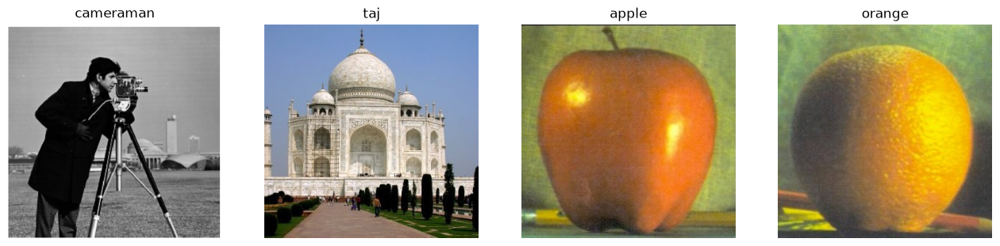

In [66]:
## Load starter images

cameraman = img_as_float(io.imread('cameraman.png'))
if cameraman.ndim == 3:
    cameraman = color.rgb2gray(cameraman[..., :3])

taj = img_as_float(io.imread('taj.jpg'))
taj_gray = color.rgb2gray(taj)

apple = img_as_float(io.imread('spline/apple.jpeg'))
orange = img_as_float(io.imread('spline/orange.jpeg'))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(
    axes, [cameraman, taj, apple, orange],
    ['cameraman', 'taj', 'apple', 'orange']
):
    ax.imshow(img, cmap='gray' if img.ndim == 2 else None)
    ax.set_title(title)
    ax.axis('off')
plt.show()

## Part 1: Fun with Filters

### Part 1.1: Convolutions from Scratch

Our four-loop convolution manually multiplies each element of the kernel with the corresponding pixel of the image. Our two-loop implementation takes advantage of vectorized operations.

In [67]:
def conv2d_4loop(image, kernel, padding='same'):
    kernel = np.flip(kernel)
    kh, kw = kernel.shape
    if padding == 'same':
        ph0, ph1 = kh // 2, (kh - 1) // 2
        pw0, pw1 = kw // 2, (kw - 1) // 2
    elif padding == 'full':
        ph0 = ph1 = kh - 1
        pw0 = pw1 = kw - 1
    else:
        raise ValueError(f"unknown padding mode: {padding}")
    padded = np.pad(image, ((ph0, ph1), (pw0, pw1)), mode='constant')
    oh, ow = padded.shape[0] - kh + 1, padded.shape[1] - kw + 1
    res = np.zeros((oh, ow))

    for r in range(oh):
        for c in range(ow):
            acc = 0.0
            for kr in range(kh):
                for kc in range(kw):
                    acc += padded[r+kr, c+kc] * kernel[kr][kc]

            res[r][c] = acc

    return res

def conv2d_2loop(image, kernel, padding='same'):
    kernel = np.flip(kernel)
    kh, kw = kernel.shape
    if padding == 'same':
        ph0, ph1 = kh // 2, (kh - 1) // 2
        pw0, pw1 = kw // 2, (kw - 1) // 2
    elif padding == 'full':
        ph0 = ph1 = kh - 1
        pw0 = pw1 = kw - 1
    else:
        raise ValueError(f"unknown padding mode: {padding}")
    padded = np.pad(image, ((ph0, ph1), (pw0, pw1)), mode='constant')
    oh, ow = padded.shape[0] - kh + 1, padded.shape[1] - kw + 1
    res = np.zeros((oh, ow))

    for r in range(oh):
        for c in range(ow):
            patch = padded[r:r+kh, c:c+kw]
            res[r, c] = np.sum(patch * kernel)

    return res

In [68]:
Dx = np.array([[1, -1]])
Dy = np.array([[1], [-1]])

dx_cameraman = convolve2d(cameraman, Dx, mode='same')
dy_cameraman = convolve2d(cameraman, Dy, mode='same')
gradient_magnitude = np.sqrt(dx_cameraman**2 + dy_cameraman**2)

### Comparing results

In [69]:
import time
test = cameraman[:100, :100]        
box = np.ones((9, 9)) / 81

t = time.time(); mine4 = conv2d_4loop(test, box); print('4-loop:', time.time()-t)
t = time.time(); mine2 = conv2d_2loop(test, box); print('2-loop:', time.time()-t)
t = time.time(); scipy_r = convolve2d(test, box, mode='same', boundary='fill'); print('scipy:', time.time()-t)

print('4loop vs scipy max diff:', np.abs(mine4 - scipy_r).max())
print('2loop vs scipy max diff:', np.abs(mine2 - scipy_r).max())

mine4_full = conv2d_4loop(test, box, padding='full')
scipy_full = convolve2d(test, box, mode='full', boundary='fill')
print('full-mode shapes match:', mine4_full.shape == scipy_full.shape)
print('full-mode max diff:', np.abs(mine4_full - scipy_full).max())

# Dx is an even-sized (1x2) kernel -- checks that 'same' padding is correctly
# asymmetric, not just kh//2 on both sides.
Dx_test = np.array([[1, -1]])
mine_dx = conv2d_2loop(test, Dx_test)
scipy_dx = convolve2d(test, Dx_test, mode='same', boundary='fill')
print('Dx same-mode max diff:', np.abs(mine_dx - scipy_dx).max())

4-loop: 0.13105010986328125
2-loop: 0.015548944473266602
scipy: 0.0006721019744873047
4loop vs scipy max diff: 1.5543122344752192e-15
2loop vs scipy max diff: 5.551115123125783e-16
full-mode shapes match: True
full-mode max diff: 1.5543122344752192e-15
Dx same-mode max diff: 0.0


The 2-loop implementation is nearly 8 times faster then the 4-loop implementation, but scipy's implementation is ~23 times faster than the 2-loop implementation! Both padding modes match scipy exactly. Boundary handling is the same as scipy's `boundary='fill'`: zero-pad, so edge pixels see fabricated zeros instead of real neighbors, which slightly dims/darkens results near the border.

### Convolving Myself

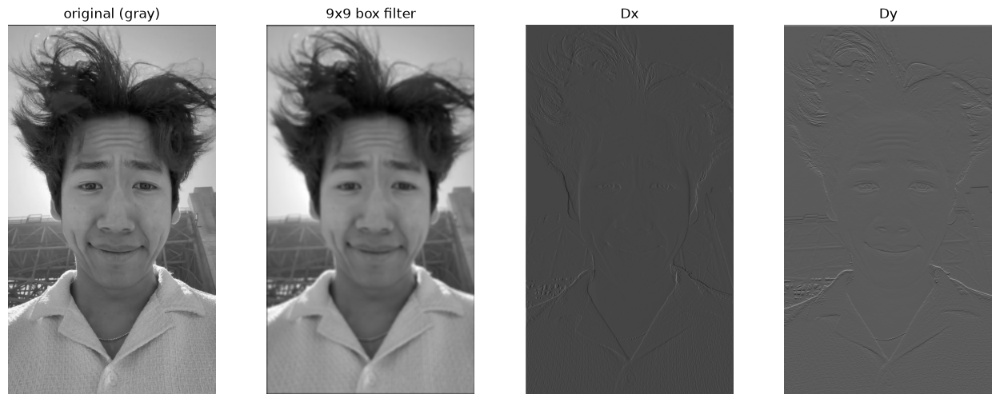

In [70]:
myself = img_as_float(io.imread('myself.jpeg'))
myself_gray = color.rgb2gray(myself)

box_9x9 = np.ones((9, 9)) / 81.0
Dx = np.array([[1, -1]])
Dy = np.array([[1], [-1]])

myself_box = conv2d_2loop(myself_gray, box_9x9)
myself_dx = conv2d_2loop(myself_gray, Dx)
myself_dy = conv2d_2loop(myself_gray, Dy)

fig, axes = plt.subplots(1, 4, figsize=(16, 6))
for ax, img, title in zip(
    axes,
    [myself_gray, myself_box, myself_dx, myself_dy],
    ['original (gray)', '9x9 box filter', 'Dx', 'Dy']
):
    ax.imshow(img, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.show()

### Part 1.2: Finite Difference Operator

Next, we convolve the cameraman image with finite difference operators **D_x** and **D_y** and show the gradient magnitude image.

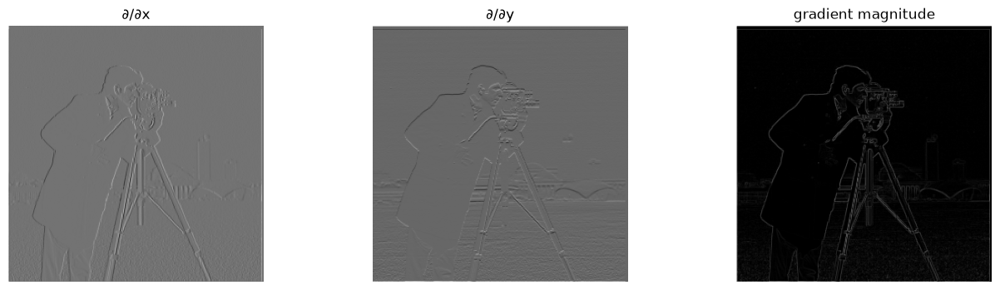

In [71]:
dx = convolve2d(cameraman, Dx, mode='same', boundary='fill')
dy = convolve2d(cameraman, Dy, mode='same', boundary='fill')
grad_mag = np.sqrt(dx**2 + dy**2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, img, title in zip(axes,
        [dx, dy, grad_mag],
        ['∂/∂x', '∂/∂y', 'gradient magnitude']):
    ax.imshow(img, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.show()

We use a slider to test various values for the threshold. We display the gradient magnitude image.

In [72]:
%matplotlib inline
from ipywidgets import interact, FloatSlider

def show_edges(threshold):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(grad_mag > threshold, cmap='gray')
    ax.set_title(f'edges (threshold = {threshold:.3f})')
    ax.axis('off')
    plt.show()

interact(show_edges,
         threshold=FloatSlider(min=0.0, max=grad_mag.max(),
                               step=0.005, value=0.2));

interactive(children=(FloatSlider(value=0.2, description='threshold', max=1.4142135623730951, step=0.005), Out…

The edges of the subject (cameraman + camera setup) are most visible when the threshold is around 0.250 -- lower thresholds (0.090) capture the edges in the background buildings, but also admit more noise.

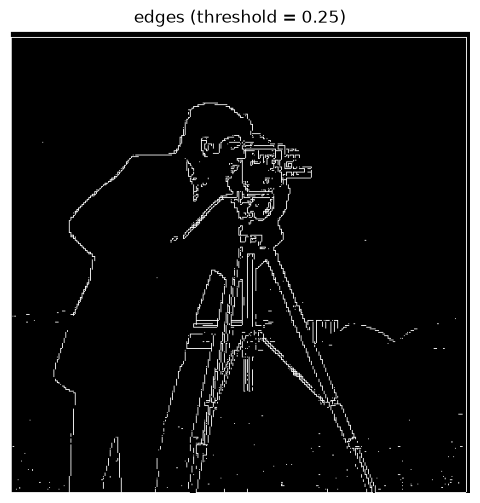

In [9]:
threshold = 0.250
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(grad_mag > threshold, cmap='gray')
ax.set_title(f'edges (threshold = {threshold})')
ax.axis('off')
plt.show()

### Part 1.3: Derivative of Gaussian (DoG) Filter

To get less noisy results, we use a Gaussian filter.

In [73]:
def gaussian_kernel_2d(size, sigma):
    k1d = cv2.getGaussianKernel(size, sigma)
    return k1d @ k1d.T

Method 1: convolve the image with the gaussian, then convolve the result with Dx and Dy.

In [74]:
G = gaussian_kernel_2d(11, 2)
blurred = convolve2d(cameraman, G, mode='same', boundary='fill')

dx_b = convolve2d(blurred, Dx, mode='same', boundary='fill')
dy_b = convolve2d(blurred, Dy, mode='same', boundary='fill')
grad_mag_blur = np.sqrt(dx_b**2 + dy_b**2)
edges_blur = grad_mag_blur > 0.08     

Method 2: Convolve Dx and Dy with the gaussian, then convolve the image with the result.

In [75]:
DoG_x = convolve2d(G, Dx, mode='full', boundary='fill')
DoG_y = convolve2d(G, Dy, mode='full', boundary='fill')

dx_dog = convolve2d(cameraman, DoG_x, mode='same', boundary='fill')
dy_dog = convolve2d(cameraman, DoG_y, mode='same', boundary='fill')

grad_mag_dog = np.sqrt(dx_dog**2 + dy_dog**2)

print('max diff:', np.abs(grad_mag_blur - grad_mag_dog).max())

max diff: 0.3997172928805899


The second method is only one convolutions **against** the image; the first method is two.

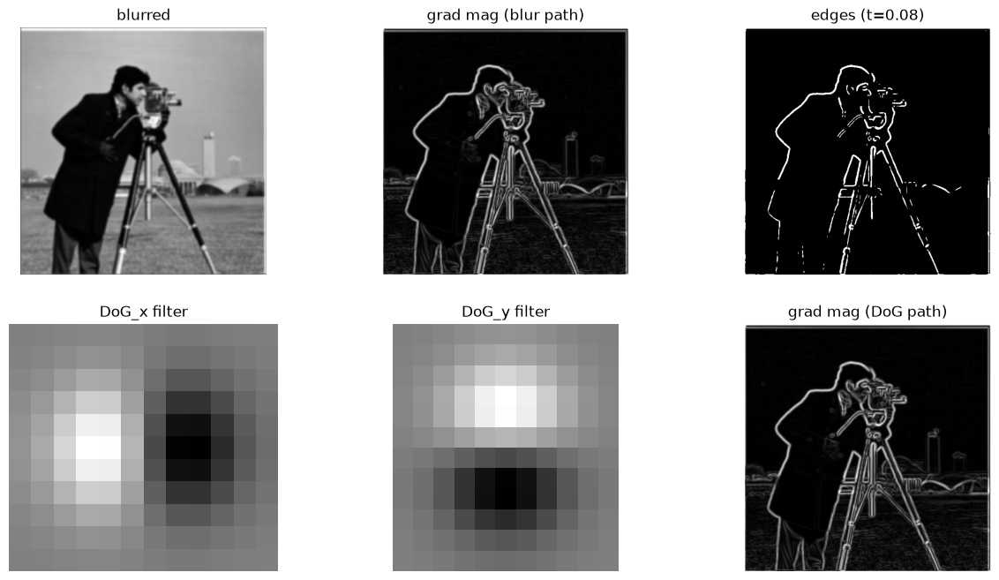

In [76]:
border = 6
shared_vmax = max(grad_mag_blur[border:-border, border:-border].max(),
                   grad_mag_dog[border:-border, border:-border].max())

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
imgs = [blurred, grad_mag_blur, edges_blur, DoG_x, DoG_y, grad_mag_dog]
titles = ['blurred', 'grad mag (blur path)', 'edges (t=0.08)',
          'DoG_x filter', 'DoG_y filter', 'grad mag (DoG path)']
vmaxes = [None, shared_vmax, None, None, None, shared_vmax]
for ax, img, t, vmax in zip(axes.flat, imgs, titles, vmaxes):
    ax.imshow(img, cmap='gray', vmax=vmax)
    ax.set_title(t)
    ax.axis('off')
plt.show()

We see that grad_mag_blur (top-middle) and grad_mag_dog (bottom-right) are identical: blurring-then-differentiating and differentiating-a-blurred-kernel-then-applying gives the same result.

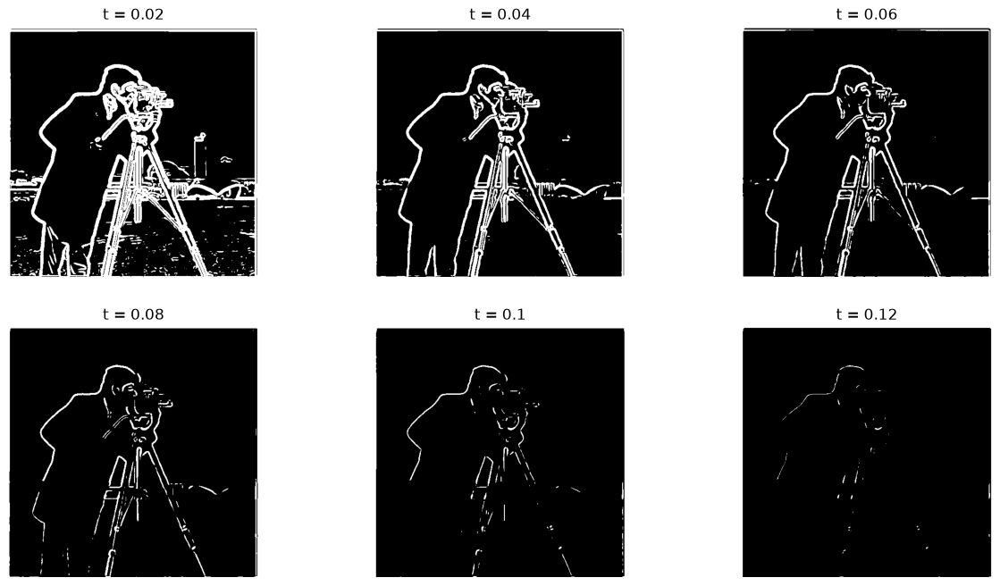

In [77]:
thresholds = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, t in zip(axes.flat, thresholds):
    ax.imshow(grad_mag_blur > t, cmap='gray')   # use grad_mag_blur for 1.3
    ax.set_title(f't = {t}')
    ax.axis('off')
plt.show()

### Part 2.1: Image "Sharpening"

Here we implement the unsharp masking technique: we use a Gaussian filter to derive only the low frequencies, subtract this from the original image to get the high frequencies of the image, then add these frequencies (amplified by a multiplicative __alpha___ factor) to the original image.

In [78]:
def blur_color(image, sigma):
    G = gaussian_kernel_2d(6*sigma + 1, sigma)
    if image.ndim == 2:
        return convolve2d(image, G, mode='same', boundary='fill')
    out = np.zeros_like(image)
    for c in range(image.shape[2]):
        out[..., c] = convolve2d(image[..., c], G, mode='same', boundary='fill')
    return out

def unsharp_mask(image, sigma, alpha):
    blurred = blur_color(image, sigma)
    return np.clip(image + alpha * (image - blurred), 0, 1)

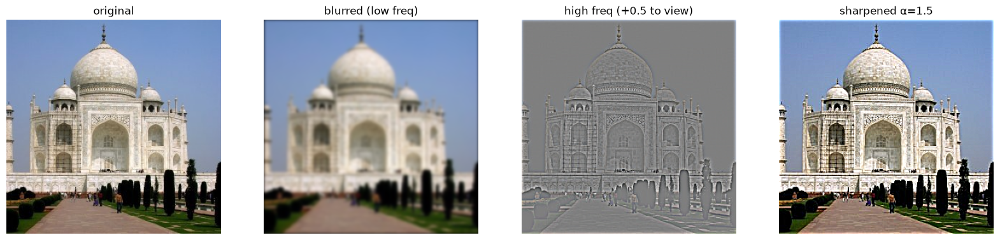

In [79]:
sharpened_taj = unsharp_mask(taj, sigma=2, alpha=1.5)
blurred = blur_color(taj, sigma=2)
high_freq = taj - blurred

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, img, t in zip(axes,
        [taj, blurred, np.clip(high_freq + 0.5, 0, 1), sharpened_taj],
        ['original', 'blurred (low freq)', 'high freq (+0.5 to view)', 'sharpened α=1.5']):
    ax.imshow(img)
    ax.set_title(t); ax.axis('off')
plt.show()

We vary alpha to see how the amount of sharpening changes the result.

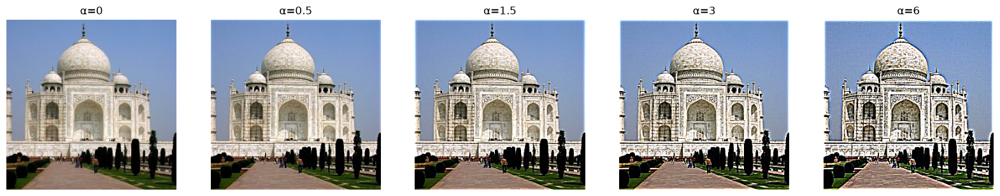

In [80]:
alphas = [0, 0.5, 1.5, 3, 6]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 5))
for ax, a in zip(axes, alphas):
    ax.imshow(unsharp_mask(taj, sigma=2, alpha=a))
    ax.set_title(f'α={a}')
    ax.axis('off')
plt.show()

To evaluate, let's blur an image and try to re-sharpen it. We pick an image with text so it's easier to tell the difference.

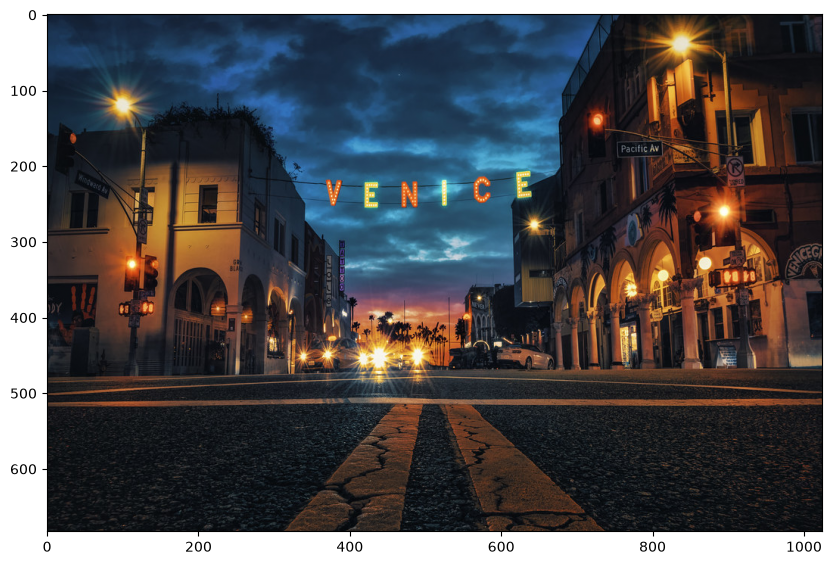

In [81]:
venice = img_as_float(io.imread('venice.jpg'))
plt.imshow(venice, cmap='gray')

We compute the MSE between the blurred image and the original plus between the resharpened image and the original.

MSE(blurred, original)     = 0.00237
MSE(resharpened, original) = 0.00175


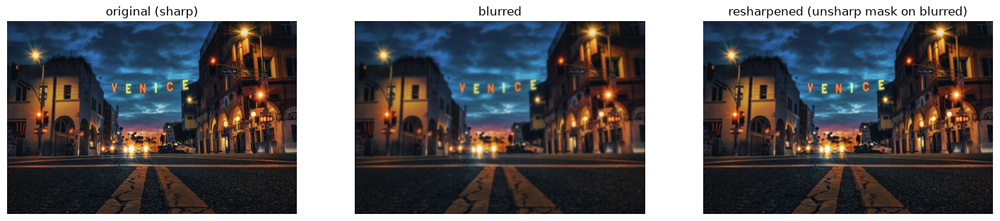

In [82]:
blurred_venice = blur_color(venice, sigma=2)
resharpened_venice = unsharp_mask(blurred_venice, sigma=2, alpha=1.5)

mse_blur_vs_orig = np.mean((blurred_venice - venice) ** 2)
mse_resharp_vs_orig = np.mean((resharpened_venice - venice) ** 2)
print(f'MSE(blurred, original)     = {mse_blur_vs_orig:.5f}')
print(f'MSE(resharpened, original) = {mse_resharp_vs_orig:.5f}')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img, t in zip(axes,
        [venice, blurred_venice, resharpened_venice],
        ['original (sharp)', 'blurred', 'resharpened (unsharp mask on blurred)']):
    ax.imshow(img)
    ax.set_title(t); ax.axis('off')
plt.show()

The resharpened image looks crisper than the blurred one. Unsharp masking pulls the blurred image back toward the original (MSE drops from ~0.00237 to ~0.00175, about a 26% reduction) but does not fully recover it. Blurring destroys high-frequency information. 

### Part 2.2: Hybrid Images

Now we explore hybrid images, which involve blending the high-frequency parts of one image with the low-frequency parts of another.

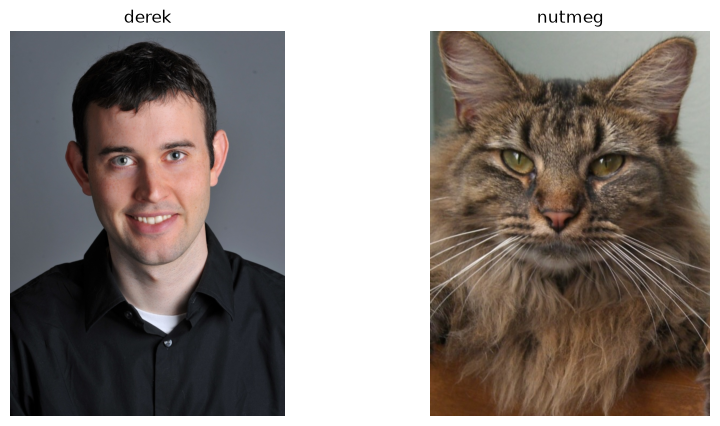

In [83]:
## Load hybrid image starter files (Derek and Nutmeg)
from align_image_code import align_images

derek = img_as_float(io.imread('DerekPicture.jpg'))
nutmeg = img_as_float(io.imread('nutmeg.jpeg'))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in zip(axes, [derek, nutmeg], ['derek', 'nutmeg']):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
plt.show()

In [84]:
import sys
print(sys.executable)
import ipympl
print(ipympl.__file__)

/Users/puthyrathy/Desktop/cs180/proj1/.venv/bin/python3.11
/Users/puthyrathy/Desktop/cs180/proj1/.venv/lib/python3.11/site-packages/ipympl/__init__.py


In [85]:
%matplotlib widget
import matplotlib
print(matplotlib.get_backend())

widget


In [86]:
%matplotlib qt
nutmeg_aligned, derek_aligned = align_images(nutmeg, derek)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in zip(axes, [derek_aligned, nutmeg_aligned], ['derek (aligned)', 'nutmeg (aligned)']):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
plt.show()
%matplotlib inline

Please select 2 points in image 1 (no timeout -- click 2 points).
Now select the same 2 points, in the same order, in image 2.


With the images aligned, we build the hybrid: high-pass Nutmeg (sharp features, seen up close) and low-pass Derek (overall shape/color, seen from far away), then add them together. We pick σ1=4 and σ2=8 by eye -- σ1 small enough to keep only Nutmeg's fine fur/whisker detail, σ2 large enough to erase Derek's features but keep his coarse shape/coloring.

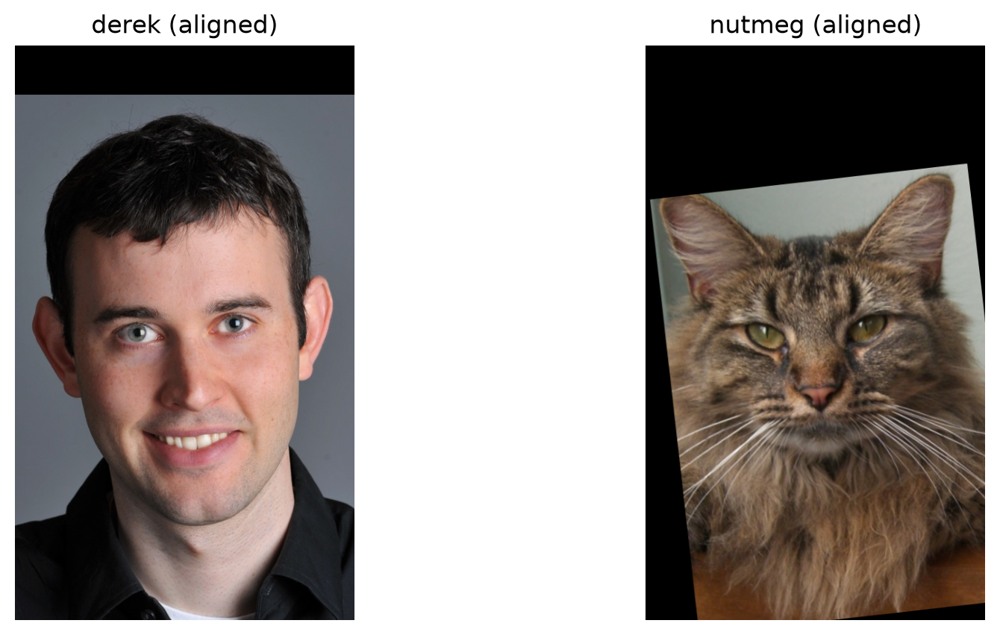

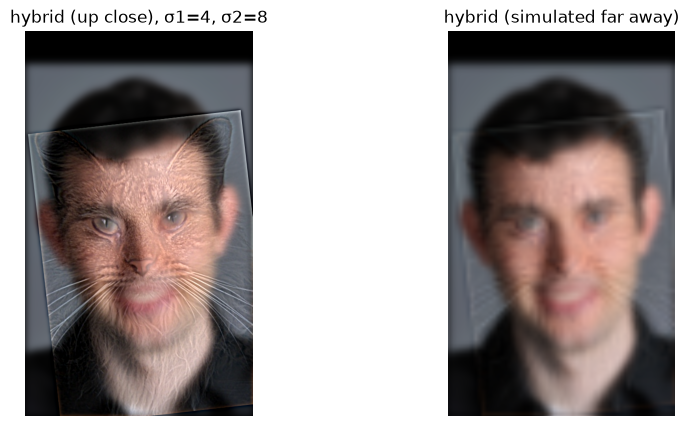

In [87]:
def hybrid_image(im1, im2, sigma1, sigma2):
    """im1: high-sf image (kept sharp). im2: low-sf image (kept blurry)."""
    high = im1 - blur_color(im1, sigma1)
    low = blur_color(im2, sigma2)
    return np.clip(high + low, 0, 1)

sigma1, sigma2 = 4, 8
hybrid = hybrid_image(nutmeg_aligned, derek_aligned, sigma1, sigma2)

from skimage.transform import resize

def simulate_distance_view(image, shrink_factor=8):
    small = resize(image, (image.shape[0] // shrink_factor, image.shape[1] // shrink_factor),
                    anti_aliasing=True)
    return resize(small, image.shape, anti_aliasing=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(hybrid); axes[0].set_title(f'hybrid (up close), σ1={sigma1}, σ2={sigma2}'); axes[0].axis('off')
axes[1].imshow(simulate_distance_view(hybrid)); axes[1].set_title('hybrid (simulated far away)'); axes[1].axis('off')
plt.show()

`simulate_distance_view` shrinks the image way down then resizes it back up — the shrink step throws away fine detail, and the upsize interpolates, so the result approximates what the eye perceives from far away.

In [88]:
def fft_log_magnitude(image):
    return np.log(np.abs(np.fft.fftshift(np.fft.fft2(image))) + 1e-8)

**Frequency analysis for the Derek/Nutmeg hybrid:** log-magnitude Fourier transforms of both inputs, both filtered versions, and the final hybrid.

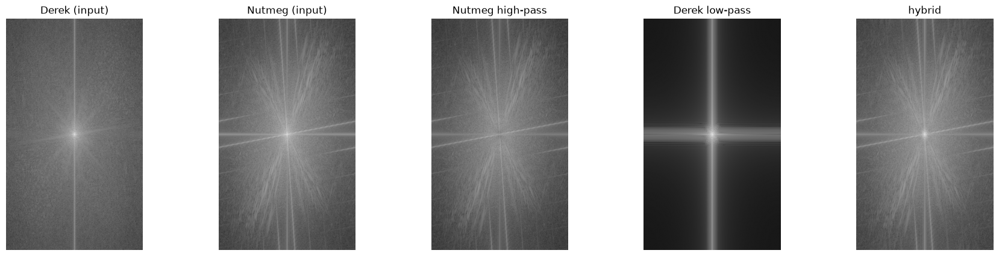

In [89]:
nutmeg_high = nutmeg_aligned - blur_color(nutmeg_aligned, sigma1)
derek_low = blur_color(derek_aligned, sigma2)

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
imgs = [color.rgb2gray(derek_aligned), color.rgb2gray(nutmeg_aligned),
        color.rgb2gray(np.clip(nutmeg_high + 0.5, 0, 1)), color.rgb2gray(derek_low),
        color.rgb2gray(hybrid)]
titles = ['Derek (input)', 'Nutmeg (input)', 'Nutmeg high-pass', 'Derek low-pass', 'hybrid']
for ax, img, t in zip(axes, imgs, titles):
    ax.imshow(fft_log_magnitude(img), cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.show()

We see that between the two, the image of Nutmeg has much more high-frequency detail, which makes it the natural candidate for a high-pass filter. The image of Derek gets the low-pass filter. 

The high-pass filter hollows out the center of Nutmeg's Fourier spectrum, leaving only high-frequency detail. The low-pass filter keeps the center of Derek's Fourier spectrum and collapses the edges to black. 

The hybrid is the union of Derek's bright center and Nutmeg's radiating outer streaks.

Now we create a few more hybrids.

#### Hybrid #2: Baby & Skull

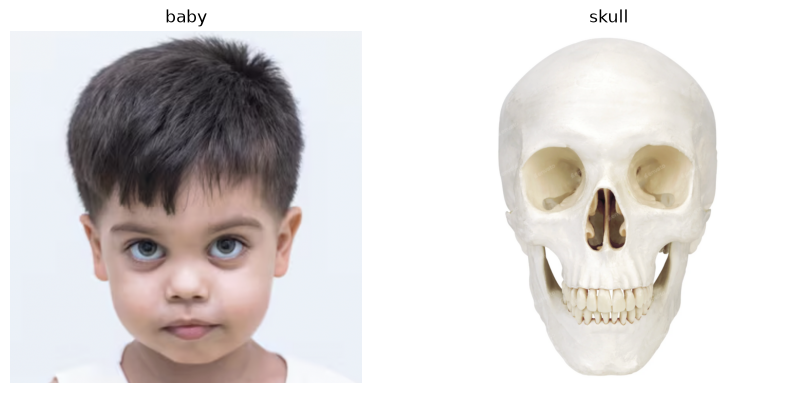

Please select 2 points in image 1 (no timeout -- click 2 points).
Now select the same 2 points, in the same order, in image 2.


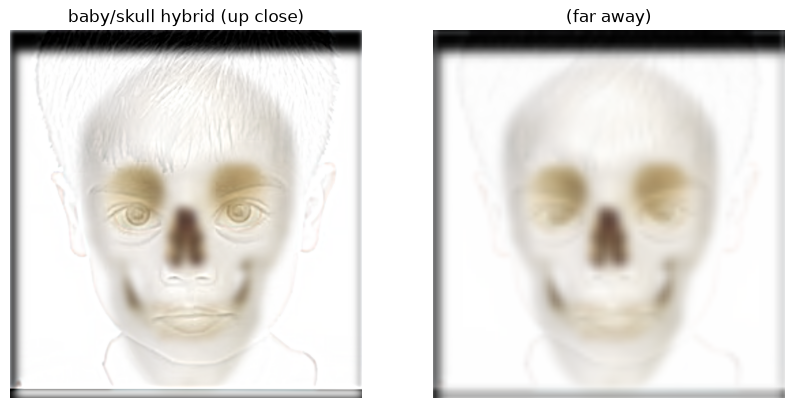

In [90]:
def resize_max_dim(image, max_dim=800):
    """Shrink image so its longer side is max_dim (no-op if already smaller)."""
    scale = max_dim / max(image.shape[:2])
    if scale >= 1:
        return image
    new_shape = (int(image.shape[0] * scale), int(image.shape[1] * scale))
    return resize(image, new_shape, anti_aliasing=True)

baby = resize_max_dim(img_as_float(io.imread('baby.png'))[..., :3])
skull = resize_max_dim(img_as_float(io.imread('skull.png'))[..., :3])

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in zip(axes, [baby, skull], ['baby', 'skull']):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
plt.show()

%matplotlib qt
baby_aligned, skull_aligned = align_images(baby, skull)
%matplotlib inline

hybrid_baby_skull = hybrid_image(baby_aligned, skull_aligned, sigma1=4, sigma2=8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(hybrid_baby_skull); axes[0].set_title('baby/skull hybrid (up close)'); axes[0].axis('off')
axes[1].imshow(simulate_distance_view(hybrid_baby_skull)); axes[1].set_title('(far away)'); axes[1].axis('off')
plt.show()

#### Hybrid #3: Bayon & Buddha
Click 2 matching points on each face (e.g. both eyes) for alignment.

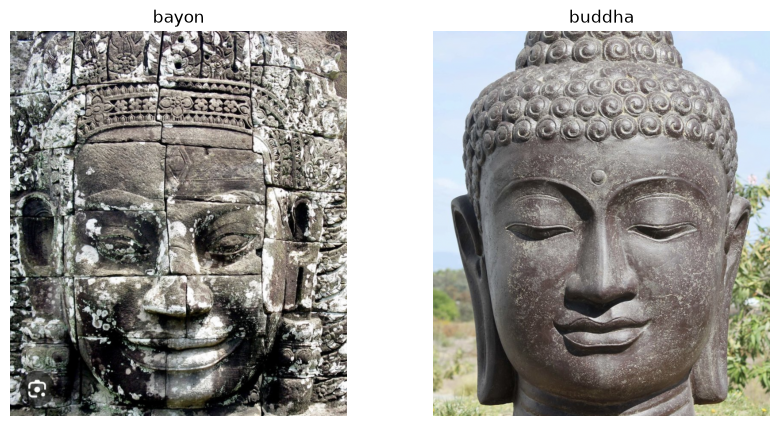

Please select 2 points in image 1 (no timeout -- click 2 points).
Now select the same 2 points, in the same order, in image 2.


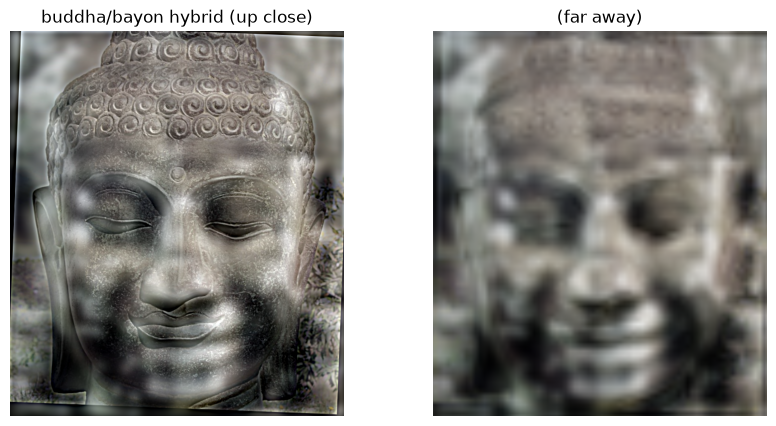

In [91]:
bayon = resize_max_dim(img_as_float(io.imread('bayon.jpg')))
buddha = resize_max_dim(img_as_float(io.imread('buddha.jpg')))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in zip(axes, [bayon, buddha], ['bayon', 'buddha']):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
plt.show()

%matplotlib qt
buddha_aligned, bayon_aligned = align_images(buddha, bayon)
%matplotlib inline

hybrid_statues = hybrid_image(buddha_aligned, bayon_aligned, sigma1=4, sigma2=8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(hybrid_statues); axes[0].set_title('buddha/bayon hybrid (up close)'); axes[0].axis('off')
axes[1].imshow(simulate_distance_view(hybrid_statues)); axes[1].set_title('(far away)'); axes[1].axis('off')
plt.show()

## 2.3: Gaussian and Laplacian Stacks

We now implement Gaussian and Laplacian stacks.

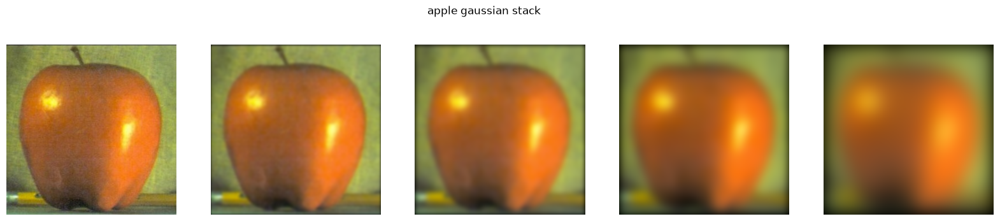

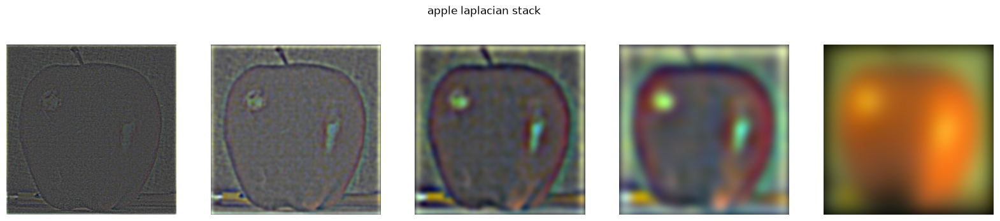

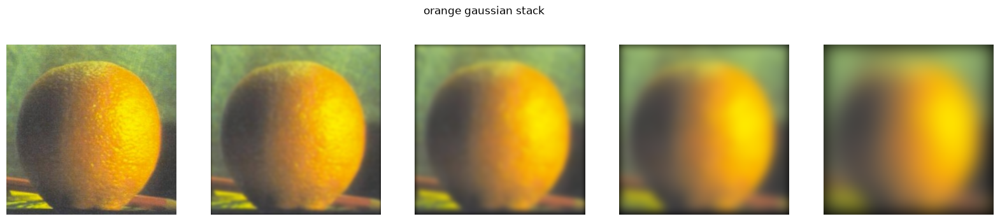

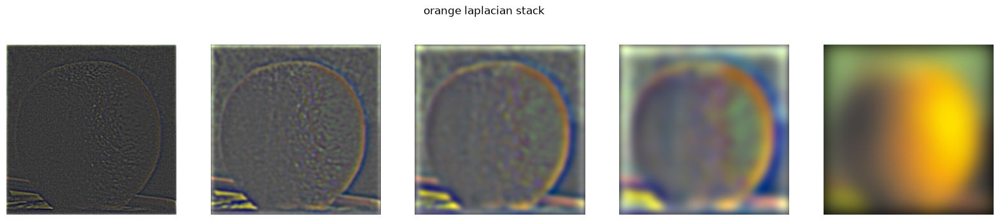

In [92]:
def gaussian_stack(image, levels, sigma=2):
    stack = [image]
    for i in range(1, levels):
        s = sigma * (2 ** (i - 1))
        blurred = blur_color(image, s)
        stack.append(blurred)
    return stack


def laplacian_stack(image, levels, sigma=2):
    G = gaussian_stack(image, levels, sigma)
    L = []
    for i in range(levels - 1):
        L.append(G[i] - G[i+1])
    L.append(G[-1])
    return L

def show_stack(stack, title):
    n = len(stack)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    for ax, level in zip(axes, stack):
        disp = (level - level.min()) / (level.max() - level.min())  # normalize to [0,1]
        ax.imshow(disp); ax.axis('off')
    fig.suptitle(title); plt.show()

apple_gauss_stack = gaussian_stack(apple, levels=5, sigma=2)
apple_lap_stack = laplacian_stack(apple, levels=5, sigma=2)

orange_gauss_stack = gaussian_stack(orange, levels=5, sigma=2)
orange_lap_stack = laplacian_stack(orange, levels=5, sigma=2)

show_stack(apple_gauss_stack, 'apple gaussian stack')
show_stack(apple_lap_stack, 'apple laplacian stack')
show_stack(orange_gauss_stack, 'orange gaussian stack')
show_stack(orange_lap_stack, 'orange laplacian stack')

In [93]:
recon = sum(apple_lap_stack)
print('reconstruction error:', np.abs(recon - apple).max())

reconstruction error: 1.1102230246251565e-16


## 2.4: Multiresolution Blending

We use what we implemented in 2.3 to blend two images together -- in the first case, an image of an apple and an image of an orange.

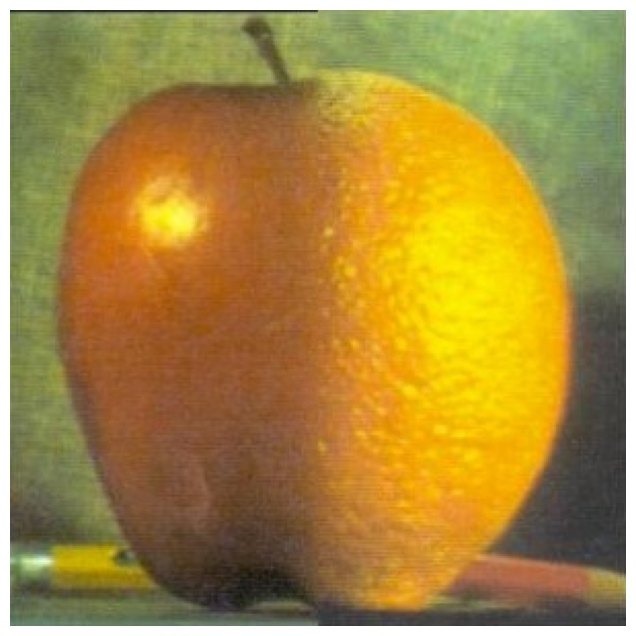

In [94]:
def blend(image1, image2, mask, levels, sigma):
    A_L = laplacian_stack(image1, levels, sigma)
    B_L = laplacian_stack(image2, levels, sigma)
    mask_G = gaussian_stack(mask, levels, sigma)

    blended_levels = []
    for i in range(levels):
        lev = mask_G[i] * A_L[i] + (1 - mask_G[i]) * B_L[i]
        blended_levels.append(lev)

    blended = sum(blended_levels)
    return np.clip(blended, 0, 1)

def vertical_mask(shape):
    mask = np.zeros(shape)
    mask[:, :shape[1] // 2] = 1
    return mask

mask = vertical_mask(apple.shape)
oraple = blend(apple, orange, mask, levels=5, sigma=2)
plt.imshow(oraple)
plt.axis('off')
plt.show()

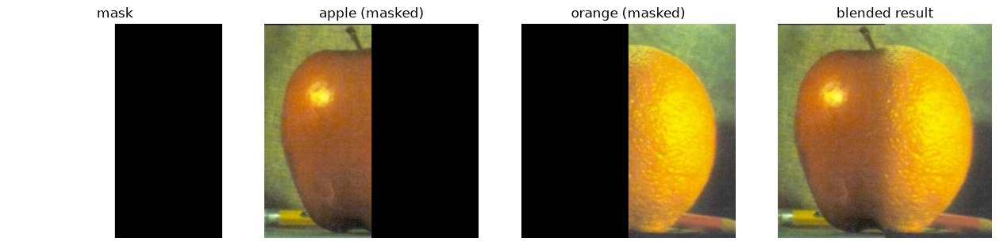

In [95]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes,
        [mask, apple * mask, orange * (1 - mask), oraple],
        ['mask', 'apple (masked)', 'orange (masked)', 'blended result']):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
plt.show()

### Tennismelon

We now try blending a different pair of images, that of a tennis ball and a watermelon.

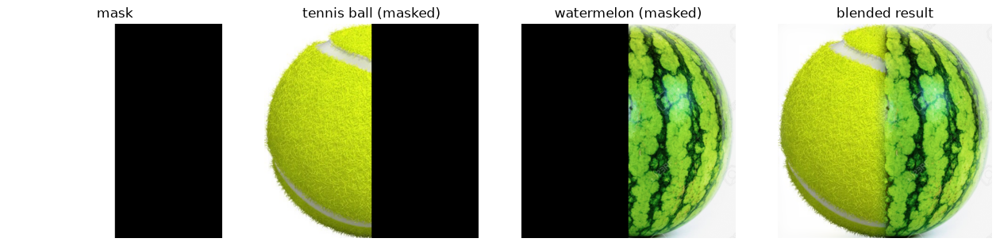

In [96]:
tennisball = img_as_float(io.imread('tennisball.jpeg'))
if tennisball.ndim == 2:
    tennisball = np.stack([tennisball] * 3, axis=-1)
watermelon = img_as_float(io.imread('watermelon.jpeg'))

target_size = 500
tennisball = resize(tennisball, (target_size, target_size), anti_aliasing=True)
watermelon = resize(watermelon, (target_size, target_size), anti_aliasing=True)

ball_mask = vertical_mask(tennisball.shape)
ball_blend = blend(tennisball, watermelon, ball_mask, levels=5, sigma=2)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes,
        [ball_mask, tennisball * ball_mask, watermelon * (1 - ball_mask), ball_blend],
        ['mask', 'tennis ball (masked)', 'watermelon (masked)', 'blended result']):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
plt.show()

Interestingly, it looks almost as if the tennis ball is encased within watermelon skin!

### Irregular Mask
Both blends above use a straight-seam mask. Here we try a circular mask instead, placed at the donut's actual hole so the eyeball sits inside it.

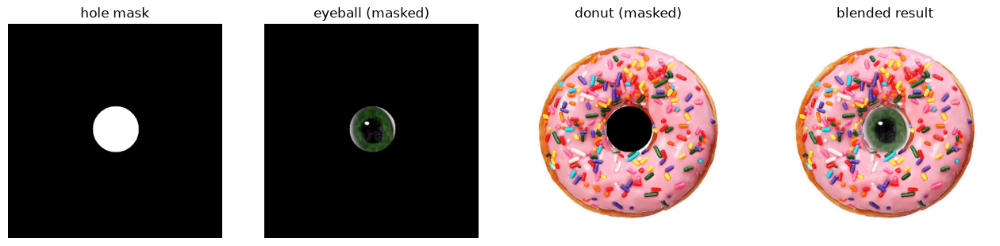

In [97]:
def circular_mask(shape, center, radius):
    h, w = shape[:2]
    cy, cx = center
    Y, X = np.ogrid[:h, :w]
    dist = np.sqrt((X - cx) ** 2 + (Y - cy) ** 2)
    m = (dist <= radius).astype(float)
    if len(shape) == 3:
        m = np.stack([m] * shape[2], axis=-1)
    return m

donut = img_as_float(io.imread('donut.jpeg'))
eyeball_full = img_as_float(io.imread('eyeball.png'))[..., :3]

# donut's hole: found by filling its silhouette and isolating the interior
# gap -- center (225, 219), equivalent-area radius ~48px
hole_center, hole_radius = (219, 225), 48

# crop around the eyeball's iris/pupil, shrink it to roughly hole-sized,
# and paste it into a blank canvas at the hole's location
cy0, cx0, half = 259, 389, 120
iris_crop = eyeball_full[cy0 - half:cy0 + half, cx0 - half:cx0 + half]
patch_size = 100
iris_patch = resize(iris_crop, (patch_size, patch_size), anti_aliasing=True)

eyeball = np.ones(donut.shape)
ph = patch_size // 2
hcy, hcx = hole_center
eyeball[hcy - ph:hcy - ph + patch_size, hcx - ph:hcx - ph + patch_size] = iris_patch

hole_mask = circular_mask(donut.shape, hole_center, hole_radius)
donut_eye = blend(eyeball, donut, hole_mask, levels=5, sigma=2)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes,
        [hole_mask, eyeball * hole_mask, donut * (1 - hole_mask), donut_eye],
        ['hole mask', 'eyeball (masked)', 'donut (masked)', 'blended result']):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
plt.show()

## What I learned

The biggest surprise: 

a convolution's kernel size sets a natural scale. The same sigma that works at one image resolution can do almost nothing at another. When I tried hybridizing images of Lincoln and Churchill, the result looked like pure Churchill because the images were too high-res for σ=8 to blur anything. 